In [42]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]
plt.rcParams['font.size'] = 16

In [43]:
import numpy as np 
import json
import os 
import h5py

from qiskit_aer import StatevectorSimulator

from symmer.operators.base import PauliwordOp, QuantumState

from qiskit_aer.primitives import SamplerV2

In [44]:
import h5py

with h5py.File("OH_data.h5", "r") as infile:

    f_op = PauliwordOp(infile["F_true_symp_matrix"][()],
                       infile["F_true_coeff_vec"][()])

    f_op_rounded = PauliwordOp(infile["F_rounded_symp_matrix"][()],
                                infile["F_rounded_coeff_vec"][()])
    
    linear_true = dict(zip(infile["lin_true_keys"][()],
                       infile["lin_true_values"][()]))
    
    quad_true = dict(zip( [(a,b) for a,b in infile["quad_true_keys"][()]],
                       infile["quad_true_values"][()]))
    

    linear_rounded = dict(zip(infile["lin_rounded_keys"][()],
                    infile["lin_rounded_values"][()]))
    
    quad_rounded   = dict(zip([(a,b) for a,b in infile["quad_rounded_keys"][()]],
                         infile["quad_rounded_values"][()]))
    
    n_elec = infile["nelec_cas"][()]
    basis_set = infile["SCF_basis"][()]
    n_spin = 2*infile["ncas"][()]
    pyscf_soln = infile["SCF_e_tot"][()]

    hf_pyscf_psi = QuantumState(infile["hf_subspace_state_matrix"][()], infile["hf_subspace_coeff_vec"][()])


print("LOADED")

LOADED


In [45]:
### write QUBO problem!

from sympy import var
variables = [var(f'x{q_idx}', bool=True) for q_idx in range(n_spin)]

problem_fn = 0
for q_idx, coeff in linear_rounded.items():
    problem_fn+= variables[q_idx]*coeff

for (q_idx1, q_idx2), coeff in quad_rounded.items():
    problem_fn+= variables[q_idx1]*variables[q_idx2]*coeff

problem_fn

80.0*x0*x1 + 48.0*x0*x10 + 64.0*x0*x11 + 68.0*x0*x2 + 72.0*x0*x3 + 16.0*x0*x4 + 16.0*x0*x5 + 64.0*x0*x6 + 68.0*x0*x7 + 56.0*x0*x8 + 56.0*x0*x9 - 294.0*x0 + 64.0*x1*x10 + 48.0*x1*x11 + 72.0*x1*x2 + 68.0*x1*x3 + 16.0*x1*x4 + 16.0*x1*x5 + 68.0*x1*x6 + 64.0*x1*x7 + 56.0*x1*x8 + 56.0*x1*x9 - 294.0*x1 + 56.0*x10*x11 + 56.0*x10*x2 + 60.0*x10*x3 + 16.0*x10*x4 + 16.0*x10*x5 + 56.0*x10*x6 + 56.0*x10*x7 + 48.0*x10*x8 + 48.0*x10*x9 - 136.0*x10 + 60.0*x11*x2 + 56.0*x11*x3 + 16.0*x11*x4 + 16.0*x11*x5 + 56.0*x11*x6 + 56.0*x11*x7 + 48.0*x11*x8 + 48.0*x11*x9 - 136.0*x11 + 80.0*x2*x3 + 16.0*x2*x4 + 20.0*x2*x5 + 64.0*x2*x6 + 68.0*x2*x7 + 48.0*x2*x8 + 60.0*x2*x9 - 296.0*x2 + 20.0*x3*x4 + 16.0*x3*x5 + 68.0*x3*x6 + 64.0*x3*x7 + 60.0*x3*x8 + 48.0*x3*x9 - 296.0*x3 + 52.0*x4*x5 + 16.0*x4*x6 + 16.0*x4*x7 + 20.0*x4*x8 + 20.0*x4*x9 - 114.0*x4 + 16.0*x5*x6 + 16.0*x5*x7 + 20.0*x5*x8 + 20.0*x5*x9 - 114.0*x5 + 68.0*x6*x7 + 52.0*x6*x8 + 52.0*x6*x9 - 278.0*x6 + 52.0*x7*x8 + 52.0*x7*x9 - 278.0*x7 + 52.0*x8*x9 - 132.0*x8

In [46]:
from itertools import combinations
def n_choose_k_vectors(n: int, k: int):
    return np.array(
        [
            [int(i in comb) for i in range(n)]
            for comb in combinations(np.arange(n), k)
        ]
    )

alph_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[0])
beta_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[1])

eigvals_counter = dict()
for alpha_term in alph_bitstrings:
    for beta_term in beta_bitstrings:
        state = np.vstack((alpha_term, beta_term)).T.reshape([f_op.n_qubits]) 
        evaluated = int(problem_fn.subs(zip(variables, state)))
        
        eigvals_counter[evaluated] = eigvals_counter.get(evaluated, 0) + 1

eigvals_counter, min(eigvals_counter.keys())

({-780: 2,
  -784: 4,
  -678: 10,
  -786: 6,
  -660: 4,
  -672: 2,
  -680: 6,
  -684: 10,
  -570: 16,
  -666: 2,
  -662: 10,
  -686: 4,
  -674: 4,
  -568: 10,
  -664: 6,
  -538: 12,
  -566: 10,
  -700: 1,
  -614: 2,
  -606: 2,
  -612: 2,
  -608: 2,
  -514: 4,
  -788: 2,
  -690: 4,
  -622: 2,
  -602: 2,
  -516: 4,
  -676: 6,
  -510: 4,
  -512: 8,
  -688: 2,
  -578: 6,
  -518: 2,
  -522: 2,
  -412: 4,
  -572: 16,
  -524: 4,
  -410: 6,
  -574: 10,
  -452: 4,
  -500: 2,
  -506: 4,
  -404: 2,
  -584: 2,
  -528: 4,
  -504: 2,
  -582: 4,
  -456: 12,
  -408: 8,
  -670: 2,
  -668: 2,
  -692: 4,
  -658: 2,
  -540: 4,
  -564: 8,
  -544: 4,
  -450: 6,
  -532: 5,
  -536: 3,
  -402: 4,
  -446: 4,
  -548: 1,
  -454: 8,
  -562: 2,
  -550: 2,
  -590: 2,
  -464: 2,
  -552: 2,
  -418: 4,
  -526: 2,
  -416: 4,
  -406: 10,
  -594: 2,
  -534: 4,
  -420: 2,
  -580: 2,
  -458: 2,
  -296: 1,
  -468: 2,
  -428: 2,
  -306: 2,
  -462: 2,
  -332: 2,
  -300: 3,
  -776: 1,
  -682: 2,
  -656: 2,
  -546: 2,
  -560: 2,

In [47]:
## the pyscf value obtained is:
e_pyscf_rounded_H = int(problem_fn.subs(zip(variables, hf_pyscf_psi.state_matrix[0])))
print(f"PySCF optimized value: {e_pyscf_rounded_H}")
print("goal is to do better than this... please note that second order methods could improve this in PySCF")
## the goal is to look at a small hard to converge system (this will be exacerbated if a larger problem is considered)

PySCF optimized value: -780
goal is to do better than this... please note that second order methods could improve this in PySCF


In [48]:
## lowest 10 eigenvalues
sorted(eigvals_counter.keys())[:10]

[-788, -786, -784, -780, -776, -700, -692, -690, -688, -686]

In [49]:
### find number of eigenstates above the PySCF value of -780
n_states_below_780 = eigvals_counter[-788] + eigvals_counter[-786] + eigvals_counter[-784]
n_states_below_780

12

In [50]:
target_states = QuantumState.from_dictionary({'000010011111': np.complex128(0.28867513459482996+0j),
                                              '000001101111': np.complex128(0.28867513459482896+0j),
                                              '000010111101': np.complex128(0.2886751345948134+0j),
                                              '000001111110': np.complex128(0.2886751345948129+0j),
                                              '000011100111': np.complex128(0.2886751345948111+0j),
                                              '000011011011': np.complex128(0.2886751345948108+0j),
                                              '000011101101': np.complex128(0.28867513459481003+0j),
                                              '000001111011': np.complex128(0.2886751345948094+0j),
                                              '000010110111': np.complex128(0.28867513459480937+0j),
                                              '000011011110': np.complex128(0.2886751345948084+0j),
                                              '000011111001': np.complex128(0.28867513459480604+0j),
                                              '000011110110': np.complex128(0.28867513459480404+0j)})
target_states._is_normalized(), target_states.n_terms

(True, 12)

In [51]:
## load output states!
output_states_list_dicke = []
L_list = np.arange(0,11)
with h5py.File("OH_output_study2.h5", "r") as infile2:
    for idx in L_list:
        output_states_list_dicke.append(QuantumState(infile2[f"psi_{idx}_state_matrix"][()],
                                                infile2[f"psi_{idx}_coeff_vec"][()]))


In [63]:
## Dicke superposition |d> analytical soln.
state_space = sum(eigvals_counter.values())
coeffs = 1/np.sqrt(state_space)

n_marked = target_states.n_terms
n_unmarked = state_space - n_marked

assert n_marked + n_unmarked == state_space
cos_coeff = np.linalg.norm(n_unmarked*[coeffs])
sin_coeff = np.linalg.norm(n_marked*[coeffs])
theta = np.arcsin(sin_coeff)


x_data = np.linspace(0, 15, 100)
probability_succ_OH_D = [ np.sin((1+2*l)*theta)**2 for l in x_data ]

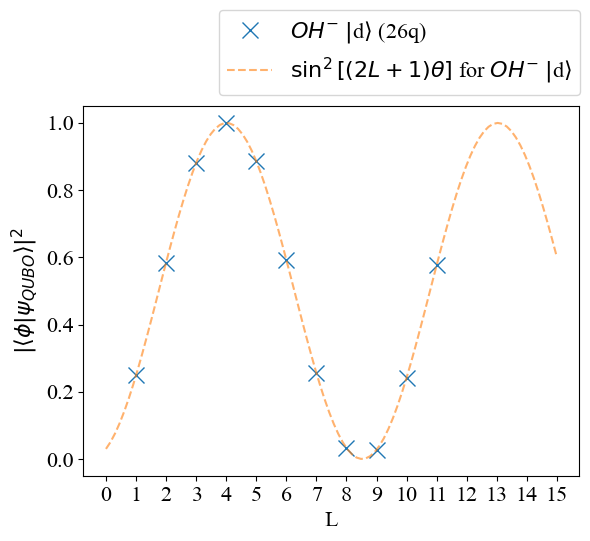

In [112]:
overlap_dicke = [np.abs(target_states.dagger * psi)**2 for psi in output_states_list_dicke]

plt.plot(L_list+1, overlap_dicke, marker="x", markersize=12, linestyle="", label=r"$OH^{-}$ $|$d$\rangle$ (26q)")
plt.plot(x_data, probability_succ_OH_D, linestyle="--", alpha=0.6, label=r"$\sin^{2}[(2L+1)θ]$ for $OH^{-}$ $|$d$\rangle$")
plt.xlabel("L")
plt.ylabel(r"$|\langle \phi| \psi_{QUBO} \rangle|^{2}$")

plt.xticks(np.arange(0,16,1))
plt.legend(bbox_to_anchor=(0.25,1))
plt.savefig('OH_dicke_L.png', dpi=300, bbox_inches='tight')
plt.show()

In [53]:
opt_iteration_psi = output_states_list_dicke[3] #<-- python indexing... this means L=4

n_samples_from_statevec = 10_000
sampled_state = opt_iteration_psi.sample_state(n_samples_from_statevec).cleanup().sort()
sampled_state

 873.000+0.000j |000011110110> +
 859.000+0.000j |000011111001> +
 858.000+0.000j |000001111110> +
 845.000+0.000j |000010111101> +
 844.000+0.000j |000001101111> +
 840.000+0.000j |000010011111> +
 838.000+0.000j |000011100111> +
 831.000+0.000j |000011101101> +
 830.000+0.000j |000001111011> +
 798.000+0.000j |000011011011> +
 796.000+0.000j |000011011110> +
 788.000+0.000j |000010110111>

In [54]:
### overwrite with solution used for paper! can comment out to generate new results
sampled_state = QuantumState.from_dictionary(
    {'000010110111': np.complex128(868+0j),
    '000010011111': np.complex128(857+0j),
    '000011011110': np.complex128(855+0j),
    '000011110110': np.complex128(854+0j),
    '000001111110': np.complex128(847+0j),
    '000011111001': np.complex128(836+0j),
    '000011101101': np.complex128(828+0j),
    '000001101111': np.complex128(824+0j),
    '000001111011': np.complex128(819+0j),
    '000011011011': np.complex128(814+0j),
    '000011100111': np.complex128(812+0j),
    '000010111101': np.complex128(786+0j)})

In [55]:
sample_number = []
energy_list   = []
state_label = []
for psi_sample in sampled_state:
    sampled_eigenstate = QuantumState(psi_sample.state_matrix[0,::-1]) # need to reverse as qiskit encocdes left to right
    energy_state =f_op.expval(sampled_eigenstate)
    energy_list.append(energy_state)
    sample_number.append(psi_sample.state_op.coeff_vec[0].real)
    int_label = sampled_eigenstate.state_matrix[0].dot(1 << np.arange(psi_sample.state_matrix.shape[-1] - 1, -1, -1))
    state_label.append(int_label)

energy_list = np.array(energy_list)
state_label = np.array(state_label)
sample_number = np.array(sample_number)

re_order = np.argsort(state_label)

energy_list = energy_list[re_order]
state_label = state_label[re_order]
sample_number = sample_number[re_order]

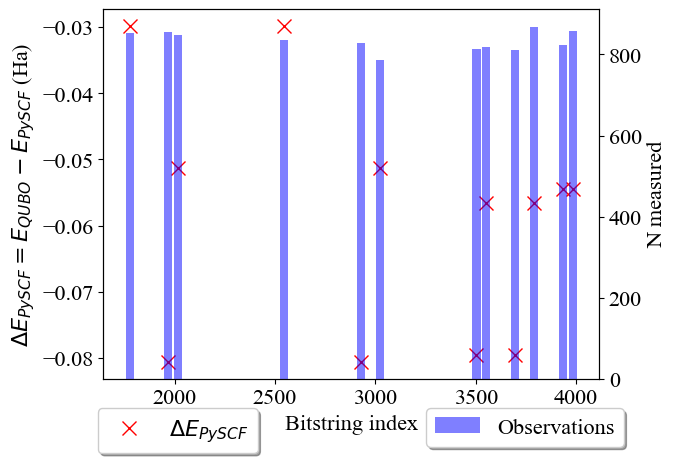

In [56]:

energy_diff = (energy_list - pyscf_soln).real

fig1=plt.figure(1)
ax=fig1.gca()
ax2=ax.twinx()


ax.plot(state_label, energy_diff, label=r'$\Delta E_{PySCF}$', color='r', marker='x', linestyle="", markersize=10)
ax2.bar(state_label, sample_number, width=40, label='Observations', color='b', alpha=0.5)

ax.set_xlabel("Bitstring index")

ax2.set_ylabel("N measured")
ax.set_ylabel(r'$\Delta E_{PySCF} = E_{QUBO}-E_{PySCF}$ (Ha)')

ax.legend()
ax2.legend()

ax.legend(loc='upper center', bbox_to_anchor=(0.15, -0.05),
          fancybox=True, shadow=True, ncol=5)
ax2.legend(loc='upper center', bbox_to_anchor=(0.85, -0.05),
          fancybox=True, shadow=True, ncol=5)


plt.savefig('OH_study2.png', dpi=300)

In [57]:
print(f"best improvemnt over PySCF: {min(energy_diff)} Ha")

best improvemnt over PySCF: -0.08060733045205382 Ha


In [37]:
from scipy.constants import physical_constants


Ha_in_J = physical_constants["Hartree energy"][0]
eV_in_J = physical_constants["electron volt"][0]

Ha_to_eV = Ha_in_J / eV_in_J

print(f"1 Ha in eV: {Ha_to_eV:0.6f}")

1 Ha in eV: 27.211386


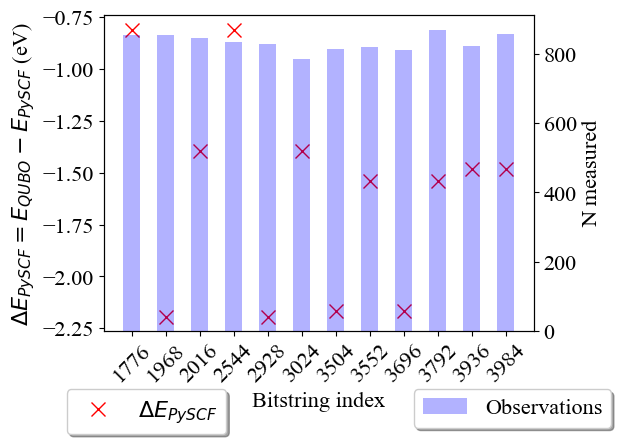

In [41]:

energy_diff = (energy_list - pyscf_soln).real

fig1=plt.figure(1)
ax=fig1.gca()
ax2=ax.twinx()

evenly_spaced = 2*np.arange(1, len(state_label)+1)

ax.plot(evenly_spaced, energy_diff * Ha_to_eV, label=r'$\Delta E_{PySCF}$', color='r', marker='x', linestyle="", markersize=10, zorder=2)
ax2.bar(evenly_spaced, sample_number, width=1, label='Observations', color='b', alpha=0.3, zorder=1)

ax.set_xlabel("Bitstring index")

# plt.xticks(state_label,rotation=45)  # set only these ticks
# plt.xticks(rotation=45)  # rotate labels 45 degrees
# ax.tick_params(axis='x', labelrotation=45)
# ax.set_xticks(state_label)
# ax.set_xticklabels(state_label, rotation=80, 
#                 #    ha='right'
#                    )
ax.set_xticks(evenly_spaced)  # set evenly spaced tick positions
ax.set_xticklabels(state_label, rotation=45)


ax2.set_ylabel("N measured")
ax.set_ylabel(r'$\Delta E_{PySCF} = E_{QUBO}-E_{PySCF}$ (eV)')

ax.legend()
ax2.legend()

ax.legend(loc='upper center', bbox_to_anchor=(0.10, -0.15),
          fancybox=True, shadow=True, ncol=5)
ax2.legend(loc='upper center', bbox_to_anchor=(0.95, -0.15),
          fancybox=True, shadow=True, ncol=5)

plt.tight_layout(pad=1.2)
plt.savefig('OH_study2.png', dpi=300)